# Practical 12 - Deterministic Model

This practical has two parts. In Part A I write the Metropolis algorithm myself and check that it works. In Part B I use it on the sunspot data from Practical 11 and work out deterministic quantities, which are values that are calculated exactly from the model parameters a and b (for example the mean of the gamma distribution).

Importing the libraries and loading the sunspot data (monthly counts from 1749 to 2018). The 67 months with a count of 0 are replaced with 0.1, because a gamma distribution only allows positive values.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln

df = pd.read_csv("../sunspots_1749_2018.csv")
data = df["sunspots"].clip(lower=0.1).values

print("Number of months:", len(data))

Number of months: 3239


## Part A: Implement the Metropolis algorithm

The Metropolis algorithm gives samples from a distribution even when we can only calculate how likely a value is, not sample from it directly. It works like this:

1. Start at some value.
2. Propose a new value by adding a small random step to the current one.
3. If the new value is more likely, move to it. If it is less likely, move to it only with a probability equal to the ratio of the two likelihoods.
4. Save the current value as a sample, and repeat many times.

Here is the function. It works with any number of parameters, and I use the log of the likelihood so the numbers do not get too small.

In [2]:
def metropolis(log_target, start, proposal_sd, n_samples, seed=42):
    rng = np.random.default_rng(seed)

    current = np.array(start, dtype=float)
    current_lp = log_target(current)

    samples = np.zeros((n_samples, len(current)))
    accepted = 0

    for i in range(n_samples):
        proposal = current + rng.normal(0, proposal_sd, size=len(current))
        proposal_lp = log_target(proposal)

        if np.log(rng.uniform()) < proposal_lp - current_lp:
            current = proposal
            current_lp = proposal_lp
            accepted += 1

        samples[i] = current

    return samples, accepted / n_samples

First a quick test on a distribution where I already know the answer: a normal distribution with mean 5 and standard deviation 2. I start the chain far away at 0 and throw away the first 500 samples.

In [3]:
def log_normal_target(x):
    return -0.5 * ((x[0] - 5) / 2) ** 2

test_samples, test_rate = metropolis(log_normal_target, start=[0], proposal_sd=4, n_samples=10000)
test_samples = test_samples[500:, 0]

print("Acceptance rate:", round(test_rate, 3))
print("Sample mean:", round(test_samples.mean(), 3), "(true value 5)")
print("Sample std:", round(test_samples.std(), 3), "(true value 2)")

Acceptance rate: 0.497
Sample mean: 5.018 (true value 5)
Sample std: 1.994 (true value 2)


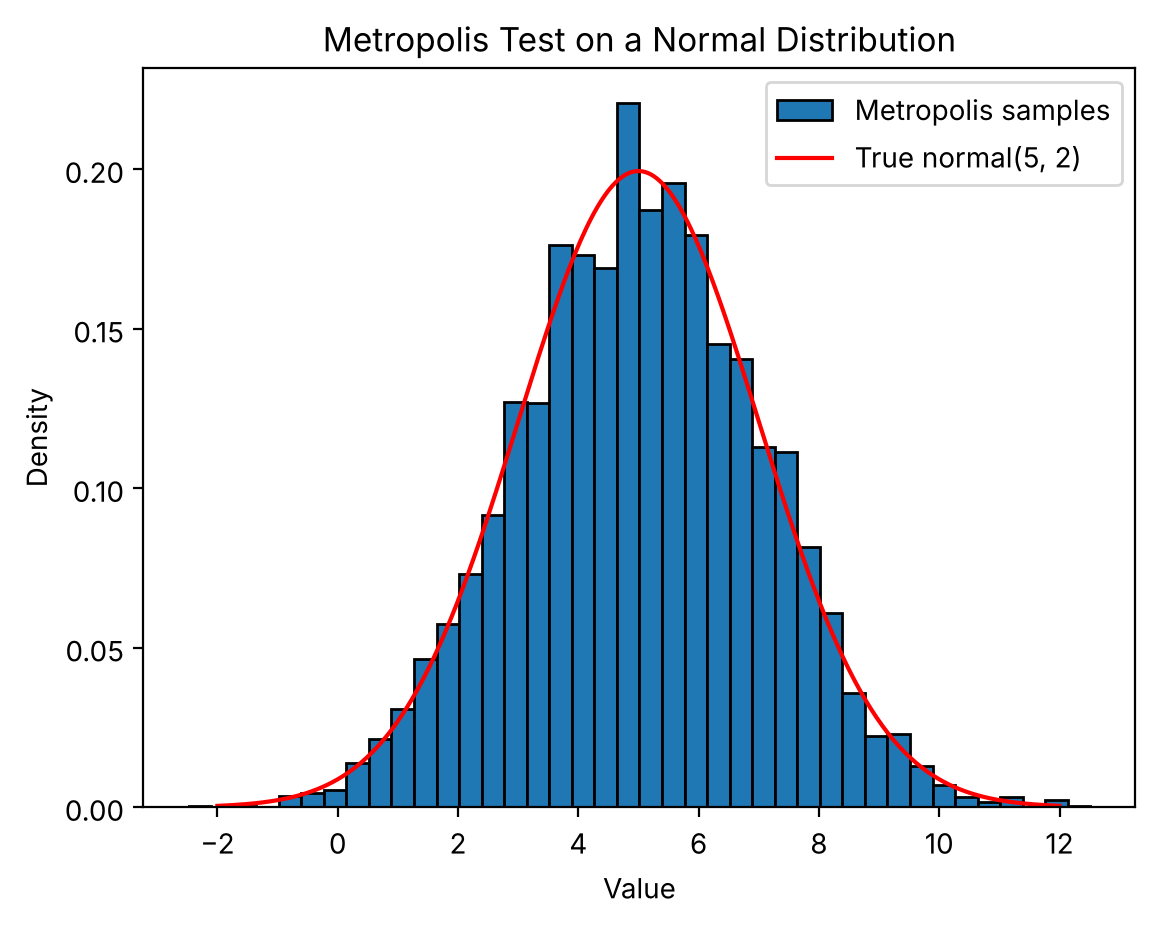

In [4]:
x = np.linspace(-2, 12, 300)

plt.hist(test_samples, bins=40, density=True, edgecolor="black", label="Metropolis samples")
plt.plot(x, stats.norm.pdf(x, 5, 2), color="red", label="True normal(5, 2)")
plt.xlabel("Value")
plt.ylabel("Density")
plt.title("Metropolis Test on a Normal Distribution")
plt.legend()
plt.show()

The sample mean and standard deviation are very close to 5 and 2, and the histogram follows the true curve, so the algorithm works.

Now I use it on the sunspot data. The model is a gamma distribution with shape a and scale b. The log likelihood below is for all the monthly counts, with a flat prior for a > 0 and b > 0. As in Practical 11, the chain starts at a = 4 and b = 10, and I drop the first 500 samples as burn-in.

In [5]:
n = len(data)
sum_data = data.sum()
sum_log_data = np.log(data).sum()

def log_posterior(params):
    a, b = params
    if a <= 0 or b <= 0:
        return -np.inf
    return -n * gammaln(a) - n * a * np.log(b) + (a - 1) * sum_log_data - sum_data / b

chain, rate = metropolis(log_posterior, start=[4, 10], proposal_sd=[0.03, 3], n_samples=5000)
posterior = chain[500:]

a_samples = posterior[:, 0]
b_samples = posterior[:, 1]

print("Acceptance rate:", round(rate, 3))
print("Samples kept after burn-in:", len(posterior))

Acceptance rate: 0.317
Samples kept after burn-in: 4500


In [6]:
estimates = pd.DataFrame({
    "mean": [a_samples.mean(), b_samples.mean()],
    "2.5%": [np.percentile(a_samples, 2.5), np.percentile(b_samples, 2.5)],
    "97.5%": [np.percentile(a_samples, 97.5), np.percentile(b_samples, 97.5)],
}, index=["a", "b"]).round(3)

print(estimates)

a_fit, loc_fit, b_fit = stats.gamma.fit(data, floc=0)
print()
print("Scipy fit for comparison: a =", round(a_fit, 3), ", b =", round(b_fit, 2))

    mean    2.5%   97.5%
a   0.98   0.939   1.019
b  84.07  79.677  89.032

Scipy fit for comparison: a = 0.979 , b = 84.18


The Metropolis estimates are very close to the direct scipy fit (a about 0.98 and b about 84).

## Part B: Deterministic model

The parameters a and b are random, because every sample gives different values. But once a and b are known, many other quantities are fixed by them with no extra randomness. These are deterministic quantities. For the gamma model:

- mean = a x b
- variance = a x b squared
- standard deviation = square root of a, times b
- probability that a month has more than 200 sunspots = 1 - the gamma cumulative probability at 200

I calculate each one for every sample of a and b. That gives a whole set of values for each quantity, so I get an estimate and a 95% range for it, and I can compare it with the real data.

In [7]:
mean_samples = a_samples * b_samples
variance_samples = a_samples * b_samples ** 2
std_samples = np.sqrt(a_samples) * b_samples
prob_200_samples = 1 - stats.gamma.cdf(200, a_samples, scale=b_samples)

In [8]:
def summary(values):
    return [values.mean(), np.percentile(values, 2.5), np.percentile(values, 97.5)]

deterministic = pd.DataFrame(
    [summary(mean_samples), summary(variance_samples), summary(std_samples), summary(prob_200_samples)],
    columns=["model mean", "2.5%", "97.5%"],
    index=["mean", "variance", "standard deviation", "P(count > 200)"],
)

deterministic["actual in data"] = [data.mean(), data.var(ddof=1), data.std(ddof=1), (data > 200).mean()]

print(deterministic.round(3))

                    model mean      2.5%     97.5%  actual in data
mean                    82.340    79.442    85.441          82.388
variance              6924.805  6366.273  7565.032        4598.866
standard deviation      83.196    79.789    86.977          67.815
P(count > 200)           0.089     0.081     0.098           0.069


The mean matches the data almost exactly: the model gives about 82.3 and the data has 82.4. But the other two do not match as well. The model standard deviation is about 83 while the data has about 68, and the model says about 8.9% of months have more than 200 sunspots while the real figure is about 6.9%. Even the 95% ranges miss the real values. So the gamma model gets the average right but spreads the counts out too much and gives too many very high months.

## Conclusion

In Part A I wrote the Metropolis algorithm and checked it on a normal distribution, where it gave the right mean and standard deviation. Applied to the sunspot data it gave a of about 0.98 and b of about 84, the same as the direct fit. In Part B I used those samples to calculate deterministic quantities. The mean (about 82) matches the data, but the model overestimates the spread and the chance of very high months, so the gamma distribution is a good description of the average but not a perfect model of how the counts vary.